# TP2 - ALUMNOS: Corominas - Fierens - Yanez Flores 

### Objetivo:

Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las cámaras digitales modernas. El video a procesar será: “focus_video.mov”.

1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper "Image Sharpness Measure for Blurred Images in Frequency Domain“ y realizar dos experimentos:

    1. Medición sobre todo el frame.
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = entre 5 y 10% del area total del frame.

    Para cada experimento se debe presentar :

    - Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la región de máximo enfoque.

**El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera automática.**

**Puntos extra:** Aplicar unsharp masking para expandir la zona de enfoque y devolver.



## 0. Bibliotecas y parámetros

Se importan las bibliotecas necesarias para la lectura y el procesamiento del video, el cálculo numérico, el análisis de resultados y su representación gráfica.

Se definen los parámetros iniciales de los experimentos. Estos valores podrán modificarse y evaluarse durante el desarrollo del trabajo práctico.

El archivo de entrada será `focus_video.mov`, ubicado en el directorio de trabajo del proyecto. Los resultados se almacenarán en la carpeta `resultados_tp2`.


In [15]:

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parámetros de los experimentos
AREA_ROI = 0.08
UMBRAL_FOCO = 0.80

# Parámetros del punto extra: unsharp masking
SIGMA_UNSHARP = 0.7
GANANCIA_UNSHARP = 0.8
MARGEN_UNSHARP = 24

# Archivo de entrada
VIDEO = Path("focus_video.mov")

if not VIDEO.is_file():
    raise FileNotFoundError(
        f"No se encontró {VIDEO.name} en {Path.cwd()}"
    )

# Verificar archivo de entrada
print("Video:", VIDEO.resolve())


Video: C:\Users\julif\CEIA_VpC\focus_video.mov



## 1. Métrica de enfoque en el dominio de la frecuencia

Se implementa el algoritmo propuesto por De y Masilamani (2013), *Image Sharpness Measure for Blurred Images in Frequency Domain*, sección 3.1.

El método se basa en que una imagen enfocada suele contener mayor información de alta frecuencia espacial que una imagen desenfocada.

El algoritmo consta de seis pasos:

1. Calcular la transformada de Fourier bidimensional de la imagen.
2. Desplazar el origen del espectro de frecuencias al centro.
3. Calcular la magnitud del espectro.
4. Obtener la magnitud máxima del espectro, $M$.
5. Contar los componentes cuya magnitud supera el umbral $M/1000$.
6. Calcular la métrica de enfoque:

$$
FM=\frac{T_H}{N \cdot M_{\mathrm{img}}}
$$

Donde:

- $T_H$: cantidad de componentes espectrales que superan el umbral.
- $N$ y $M_{\mathrm{img}}$: dimensiones de la imagen analizada.

La métrica $FM$ representa la proporción de componentes espectrales que superan el umbral establecido. Valores mayores indican, en general, imágenes con mayor contenido frecuencial y potencialmente mejor enfocadas.

El algoritmo se aplicará a imágenes en escala de grises, tanto al fotograma completo como a una ROI central.


In [2]:

def frecuencia_enfoque(imagen_gris):

    # Paso 1: Transformada de Fourier bidimensional
    transformada = np.fft.fft2(imagen_gris)

    # Paso 2: Centrar el espectro
    centrada = np.fft.fftshift(transformada)

    # Paso 3: Calcular la magnitud del espectro
    magnitud = np.abs(centrada)

    # Paso 4: Determinar la magnitud máxima
    M = np.max(magnitud)

    if M == 0:
        return 0.0

    # Paso 5: Contar los componentes que superan M/1000
    TH = np.count_nonzero(magnitud > M / 1000)

    # Paso 6: Calcular la métrica
    FM = TH / imagen_gris.size

    return float(FM)


In [3]:

def recortar_roi_central(imagen, fraccion_area=0.08):

    # Dimensiones del fotograma
    alto, ancho = imagen.shape[:2]

    # Factor de escala para conservar la proporción
    escala = np.sqrt(fraccion_area)

    # Dimensiones de la ROI
    ancho_roi = round(ancho * escala)
    alto_roi = round(alto * escala)

    # Coordenadas de la esquina superior izquierda
    x0 = (ancho - ancho_roi) // 2
    y0 = (alto - alto_roi) // 2

    # Recorte central
    roi = imagen[y0:y0 + alto_roi,
                 x0:x0 + ancho_roi]

    return roi, (x0, y0, ancho_roi, alto_roi)


In [4]:

cap = cv2.VideoCapture(str(VIDEO))
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError("No se pudo leer el primer fotograma.")

# Convertimos a escala de grises
gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Obtenemos la ROI
roi, coordenadas = recortar_roi_central(gris, AREA_ROI)

# Calculamos ambas métricas
fm_completo = frecuencia_enfoque(gris)
fm_roi = frecuencia_enfoque(roi)

print(f"Dimensiones del fotograma: {gris.shape}")
print(f"Dimensiones de la ROI: {roi.shape}")
print(f"FM completo: {fm_completo:.6f}")
print(f"FM ROI: {fm_roi:.6f}")


Dimensiones del fotograma: (360, 640)
Dimensiones de la ROI: (102, 181)
FM completo: 0.007122
FM ROI: 0.056711



## 2. Lectura del video y cálculo fotograma a fotograma

Se procesa el archivo `focus_video.mov` utilizando OpenCV.

Para cada fotograma se realizan las siguientes operaciones:

1. Lectura del fotograma y conversión a escala de grises.
2. Extracción de una ROI centrada, equivalente al 8 % del área total.
3. Cálculo de la métrica de enfoque (FM) sobre el fotograma completo.
4. Cálculo de la misma métrica sobre la ROI.
5. Almacenamiento de los resultados para su posterior análisis.

Ambos experimentos utilizan los mismos fotogramas, sin modificaciones adicionales de brillo, contraste o resolución.

Se registra también el tiempo correspondiente a cada fotograma, calculado a partir de la frecuencia de adquisición del video (FPS).

El objetivo es obtener dos series temporales que permitan analizar la evolución de la métrica de enfoque y comparar el comportamiento del fotograma completo con el de la región seleccionada.


In [5]:

# Abrir el video
cap = cv2.VideoCapture(str(VIDEO))

if not cap.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO}")

# Obtener los fotogramas por segundo
fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    cap.release()
    raise RuntimeError("El video no informa FPS válidos.")

# Listas para almacenar resultados
frames_grises = []
fm_completo = []
fm_roi = []

# Procesar el video fotograma a fotograma
while True:

    # Leer un fotograma
    ok, frame = cap.read()

    if not ok:
        break

    # Convertir a escala de grises
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Extraer ROI central
    roi, coords_roi = recortar_roi_central(gris, AREA_ROI)

    # Guardar el fotograma
    frames_grises.append(gris)

    # Calcular métricas de enfoque
    fm_completo.append(frecuencia_enfoque(gris))
    fm_roi.append(frecuencia_enfoque(roi))

# Cerrar el archivo de video
cap.release()

if len(frames_grises) == 0:
    raise RuntimeError("No se pudieron leer fotogramas.")

# Convertir los resultados a arrays de NumPy
fm_completo = np.asarray(fm_completo)
fm_roi = np.asarray(fm_roi)

# Calcular el tiempo de cada fotograma
instantes_s = np.arange(len(frames_grises)) / fps

# Verificar las dimensiones
alto, ancho = frames_grises[0].shape
x0, y0, ancho_roi, alto_roi = coords_roi

area_real = 100 * ancho_roi * alto_roi / (ancho * alto)

# Mostrar información del video
print(f"Fotogramas procesados: {len(frames_grises)}")
print(f"FPS: {fps:.2f}")
print(f"Duración aproximada: {len(frames_grises)/fps:.2f} s")
print(f"Resolución: {ancho} x {alto} píxeles")
print(f"ROI: {ancho_roi} x {alto_roi} píxeles")
print(f"Área relativa de la ROI: {area_real:.2f} %")
print(f"Valores FM calculados: {len(fm_completo)} por experimento")


Fotogramas procesados: 171
FPS: 29.97
Duración aproximada: 5.71 s
Resolución: 640 x 360 píxeles
ROI: 181 x 102 píxeles
Área relativa de la ROI: 8.01 %
Valores FM calculados: 171 por experimento



## 3. Evolución temporal de la métrica de enfoque

Se representa la evolución de la métrica FM en función del tiempo para los dos experimentos:

1. **Fotograma completo:** cálculo de FM sobre la totalidad de la imagen.
2. **ROI central:** cálculo de FM sobre una región equivalente al 8 % del área total del fotograma.

Las curvas se representan sin aplicar suavizado ni otros tratamientos, con el propósito de observar directamente la respuesta del algoritmo propuesto por De y Masilamani (2013).

Se identifica el máximo de cada curva como referencia inicial para el análisis. Sin embargo, este valor no define por sí solo la región de enfoque, ya que pueden existir múltiples fotogramas con una nitidez visualmente aceptable.

Se analizarán las diferencias en la evolución de ambas métricas, sus fluctuaciones y la ubicación temporal de sus máximos.


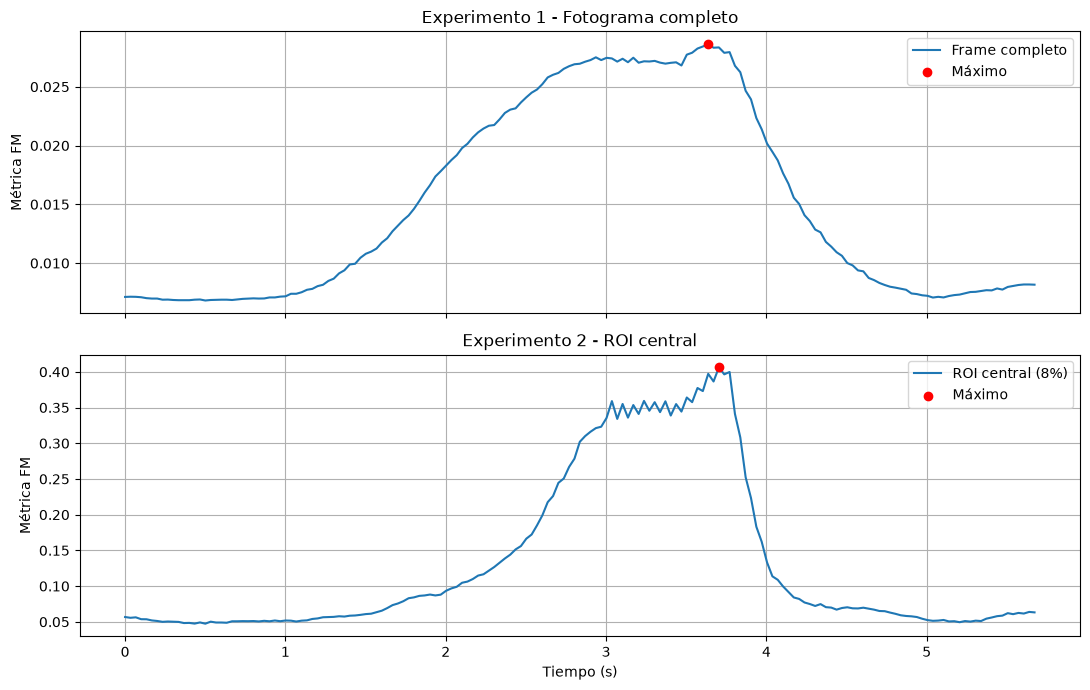

EXPERIMENTO 1 - FRAME COMPLETO
Frame del máximo: 109
Tiempo: 3.637 s
FM máximo: 0.028624

EXPERIMENTO 2 - ROI CENTRAL
Frame del máximo: 111
Tiempo: 3.704 s
FM máximo: 0.406294


In [6]:

# Identificar los máximos de las métricas
idx_max_completo = np.argmax(fm_completo)
idx_max_roi = np.argmax(fm_roi)

# Crear los gráficos
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Experimento 1: fotograma completo
axes[0].plot(instantes_s, fm_completo, label="Frame completo")
axes[0].scatter(instantes_s[idx_max_completo],
                fm_completo[idx_max_completo],
                color="red", zorder=3, label="Máximo")

axes[0].set_title("Experimento 1 - Fotograma completo")
axes[0].set_ylabel("Métrica FM")
axes[0].legend()
axes[0].grid(True)

# Experimento 2: ROI central
axes[1].plot(instantes_s, fm_roi, label="ROI central (8%)")
axes[1].scatter(instantes_s[idx_max_roi],
                fm_roi[idx_max_roi],
                color="red", zorder=3, label="Máximo")

axes[1].set_title("Experimento 2 - ROI central")
axes[1].set_xlabel("Tiempo (s)")
axes[1].set_ylabel("Métrica FM")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Mostrar los máximos
print("EXPERIMENTO 1 - FRAME COMPLETO")
print(f"Frame del máximo: {idx_max_completo}")
print(f"Tiempo: {instantes_s[idx_max_completo]:.3f} s")
print(f"FM máximo: {fm_completo[idx_max_completo]:.6f}")

print("\nEXPERIMENTO 2 - ROI CENTRAL")
print(f"Frame del máximo: {idx_max_roi}")
print(f"Tiempo: {instantes_s[idx_max_roi]:.3f} s")
print(f"FM máximo: {fm_roi[idx_max_roi]:.6f}")


### Análisis de resultados

Las dos curvas presentan el comportamiento esperado: la métrica FM aumenta durante el proceso de enfoque y disminuye cuando la imagen vuelve a desenfocarse.

El máximo se identifica en el fotograma 109 (3,637 s) para la imagen completa y en el fotograma 111 (3,704 s) para la ROI central. La diferencia de apenas dos fotogramas evidencia una buena correspondencia temporal entre ambos experimentos.

Sin embargo, se observan diferencias en la forma de las curvas. La medición sobre el fotograma completo presenta una evolución más gradual, mientras que la ROI central muestra fluctuaciones más pronunciadas cerca del máximo.

También se identifica una región relativamente amplia en la que la métrica permanece próxima a su valor máximo.

Por lo tanto, la detección del máximo absoluto resulta insuficiente para establecer el intervalo de enfoque. Es necesario definir un criterio que permita identificar automáticamente los fotogramas que presentan un nivel de enfoque aceptable.



## 4. Detección automática del intervalo de máximo enfoque

Para determinar el intervalo de máximo enfoque se implementa un criterio basado en un umbral relativo al valor máximo de la métrica FM.

El procedimiento consiste en:

1. Identificar el valor máximo de FM y el fotograma correspondiente.
2. Establecer un umbral equivalente al **80 % del valor máximo**. (ver análisis al final del punto 4)
3. Identificar los fotogramas que presentan valores de FM iguales o superiores al umbral establecido.
4. Determinar el intervalo continuo que contiene el máximo absoluto, identificando automáticamente sus límites inicial y final.

El criterio se aplica independientemente a las métricas calculadas sobre el fotograma completo y sobre la ROI central.

Se adopta inicialmente un umbral del 80 % como compromiso entre seleccionar únicamente el entorno inmediato del máximo y considerar una región más amplia de enfoque aceptable.

No se aplica suavizado, de manera que el procedimiento utiliza directamente los valores obtenidos mediante el algoritmo de De y Masilamani (2013).

El intervalo detectado representa una estimación del enfoque aceptable según el criterio adoptado y no necesariamente coincide de manera exacta con la percepción visual.


In [7]:

def detectar_intervalo_foco(fm, umbral_relativo):

    # Encontrar el máximo absoluto
    idx_max = np.argmax(fm)
    fm_max = fm[idx_max]

    # Calcular el umbral
    umbral = umbral_relativo * fm_max

    # Buscar el inicio del intervalo
    inicio = idx_max

    while inicio > 0 and fm[inicio - 1] >= umbral:
        inicio -= 1

    # Buscar el final del intervalo
    fin = idx_max

    while fin < len(fm) - 1 and fm[fin + 1] >= umbral:
        fin += 1

    return inicio, fin, idx_max, umbral


# Aplicar a los dos experimentos
inicio_completo, fin_completo, max_completo, umbral_completo = \
    detectar_intervalo_foco(fm_completo, UMBRAL_FOCO)

inicio_roi, fin_roi, max_roi, umbral_roi = \
    detectar_intervalo_foco(fm_roi, UMBRAL_FOCO)


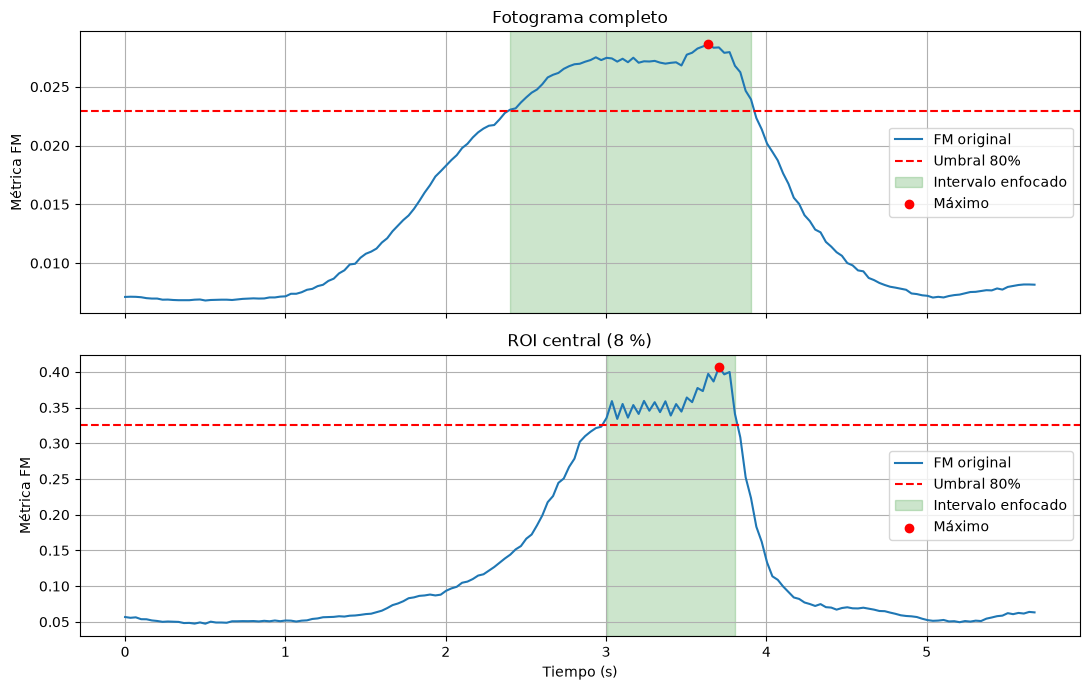


Fotograma completo
Máximo: frame 109 (3.637 s)
Inicio: frame 72 (2.402 s)
Final: frame 117 (3.904 s)
Fotogramas enfocados: 46
Umbral FM: 0.022899

ROI central (8 %)
Máximo: frame 111 (3.704 s)
Inicio: frame 90 (3.003 s)
Final: frame 114 (3.804 s)
Fotogramas enfocados: 25
Umbral FM: 0.325035


In [8]:

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

experimentos = [
    ("Fotograma completo", fm_completo,
     inicio_completo, fin_completo, max_completo, umbral_completo),

    ("ROI central (8 %)", fm_roi,
     inicio_roi, fin_roi, max_roi, umbral_roi)
]

for ax, (nombre, fm, inicio, fin, idx_max, umbral) in zip(axes, experimentos):

    # Curva original
    ax.plot(instantes_s, fm, label="FM original")

    # Umbral de enfoque
    ax.axhline(umbral, color="red", linestyle="--",
               label=f"Umbral {UMBRAL_FOCO:.0%}")

    # Intervalo enfocado
    ax.axvspan(instantes_s[inicio], instantes_s[fin],
               color="green", alpha=0.2,
               label="Intervalo enfocado")

    # Máximo absoluto
    ax.scatter(instantes_s[idx_max], fm[idx_max],
               color="red", zorder=3, label="Máximo")

    ax.set_title(nombre)
    ax.set_ylabel("Métrica FM")
    ax.legend()
    ax.grid(True)

axes[1].set_xlabel("Tiempo (s)")

plt.tight_layout()
plt.show()


# Resultados numéricos
for nombre, fm, inicio, fin, idx_max, umbral in experimentos:

    print(f"\n{nombre}")
    print(f"Máximo: frame {idx_max} ({instantes_s[idx_max]:.3f} s)")
    print(f"Inicio: frame {inicio} ({instantes_s[inicio]:.3f} s)")
    print(f"Final: frame {fin} ({instantes_s[fin]:.3f} s)")
    print(f"Fotogramas enfocados: {fin - inicio + 1}")
    print(f"Umbral FM: {umbral:.6f}")



## 5. Análisis de sensibilidad del umbral

Para evaluar la influencia del umbral relativo en la detección del intervalo enfocado, se comparan tres valores: **80 %, 85 % y 90 % del máximo de FM**.

Se aplica el mismo algoritmo de detección a ambos experimentos, utilizando las métricas originales, sin suavizado.

Para cada umbral se registran:

- Fotograma inicial y final del intervalo enfocado.
- Tiempo correspondiente a ambos límites.
- Cantidad de fotogramas clasificados como enfocados.

El objetivo es analizar la sensibilidad del detector frente a modificaciones del umbral y fundamentar la selección de un valor adecuado.


In [9]:

# Comparar la detección con distintos umbrales
filas = []

for porcentaje in [0.80, 0.85, 0.90]:

    for nombre, fm in [
        ("Frame completo", fm_completo),
        ("ROI central (8 %)", fm_roi)
    ]:

        inicio, fin, idx_max, umbral = detectar_intervalo_foco(
            fm, porcentaje
        )

        filas.append({
            "Región": nombre,
            "Umbral": f"{porcentaje:.0%}",
            "Frame inicial": inicio,
            "Frame final": fin,
            "Tiempo inicial (s)": round(instantes_s[inicio], 3),
            "Tiempo final (s)": round(instantes_s[fin], 3),
            "Frames enfocados": fin - inicio + 1
        })

# Construir y mostrar la tabla
tabla_umbrales = pd.DataFrame(filas)

display(tabla_umbrales)


,Región,Umbral,Frame inicial,Frame final,Tiempo inicial (s),Tiempo final (s),Frames enfocados
0,Frame completo,80%,72,117,2.402,3.904,46
1,ROI central (8 %),80%,90,114,3.003,3.804,25
2,Frame completo,85%,76,116,2.536,3.871,41
3,ROI central (8 %),85%,105,113,3.504,3.770,9
4,Frame completo,90%,79,115,2.636,3.837,37
5,ROI central (8 %),90%,107,113,3.570,3.770,7


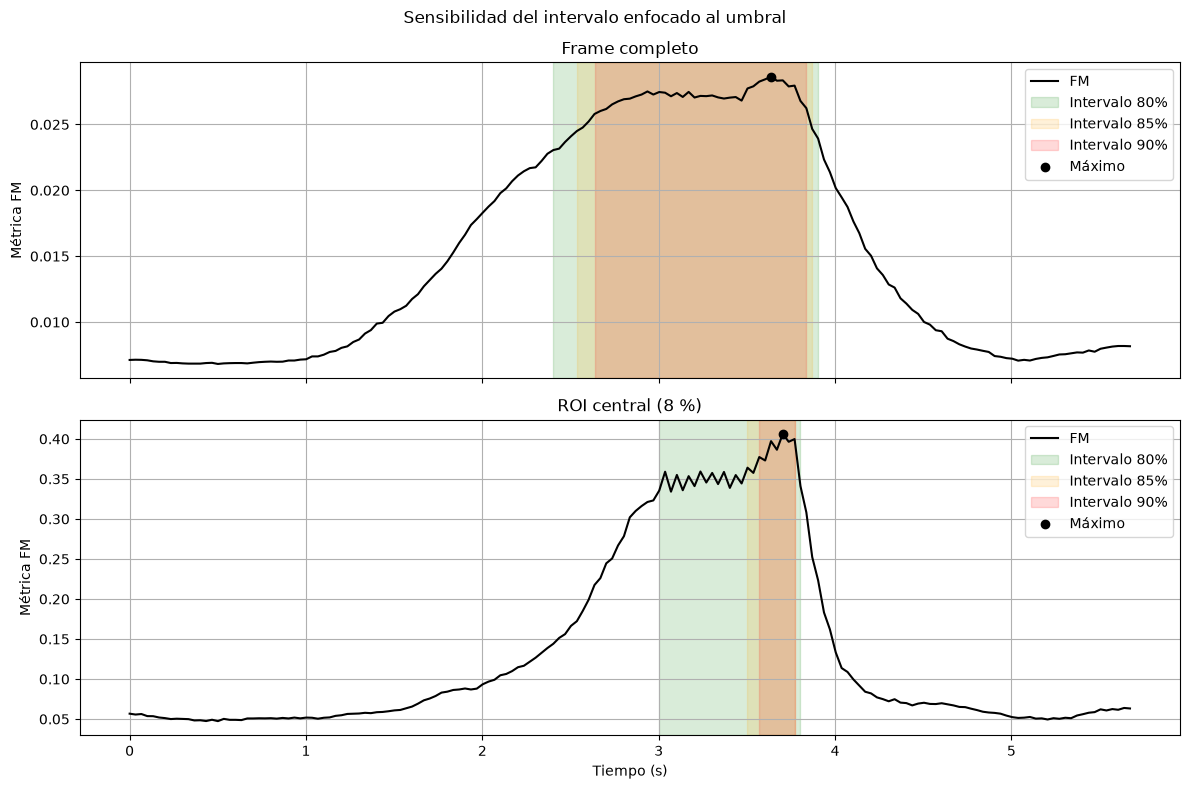

In [10]:

# Comparación visual de los intervalos detectados
umbrales = [0.80, 0.85, 0.90]
colores = ["green", "orange", "red"]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, (nombre, fm) in zip(
    axes,
    [("Frame completo", fm_completo),
     ("ROI central (8 %)", fm_roi)]
):

    # Curva de enfoque
    ax.plot(instantes_s, fm, color="black", label="FM")

    # Dibujar cada intervalo con transparencia
    for porcentaje, color in zip(umbrales, colores):

        inicio, fin, idx_max, umbral = detectar_intervalo_foco(
            fm, porcentaje
        )

        ax.axvspan(
            instantes_s[inicio],
            instantes_s[fin],
            color=color,
            alpha=0.15,
            label=f"Intervalo {porcentaje:.0%}"
        )

    # Máximo absoluto
    idx_max = np.argmax(fm)
    ax.scatter(
        instantes_s[idx_max],
        fm[idx_max],
        color="black",
        zorder=4,
        label="Máximo"
    )

    ax.set_title(nombre)
    ax.set_ylabel("Métrica FM")
    ax.grid(True)
    ax.legend()

axes[1].set_xlabel("Tiempo (s)")

plt.suptitle("Sensibilidad del intervalo enfocado al umbral")
plt.tight_layout()
plt.show()



## 6. Verificación visual de los resultados

Se seleccionan automáticamente cuatro fotogramas representativos del video:

1. Primer fotograma del video.
2. Inicio del intervalo enfocado detectado para la ROI central.
3. Fotograma correspondiente al máximo de FM de la ROI.
4. Último fotograma del video.

Se representan las imágenes en escala de grises, indicando la posición de la ROI central utilizada durante el análisis.

El objetivo es comprobar cualitativamente la correspondencia entre los valores de FM y la nitidez observada en las imágenes.

Esta verificación permite evaluar la coherencia del algoritmo, aunque no constituye una validación cuantitativa de la percepción visual.


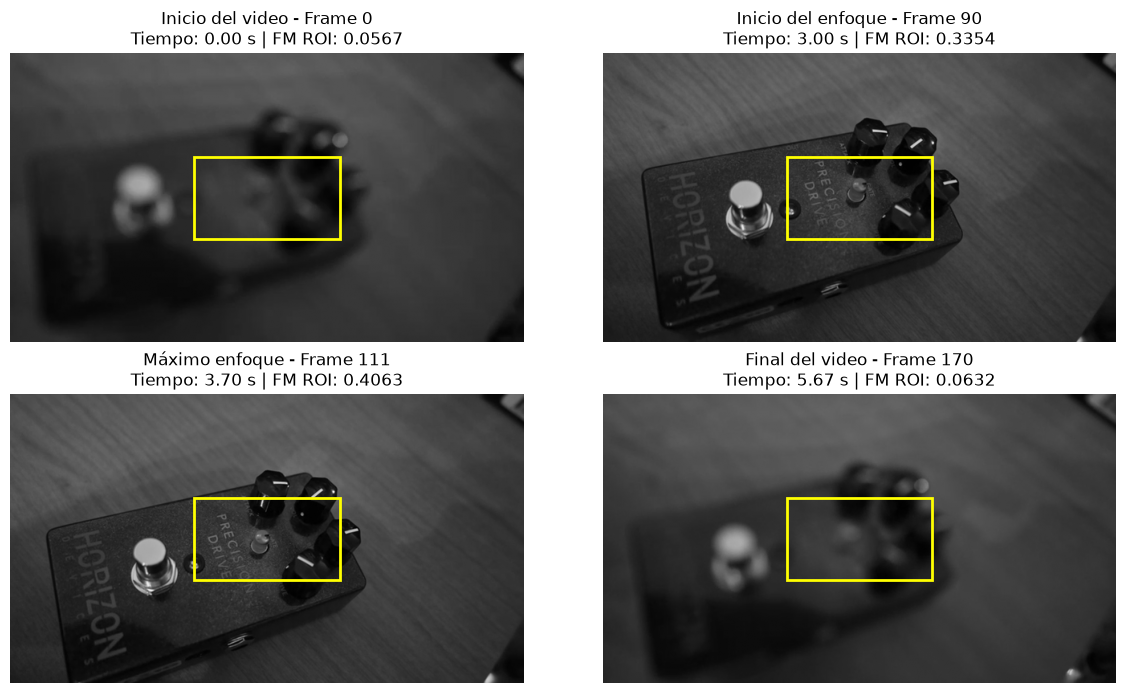

In [11]:

# Seleccionar automáticamente cuatro fotogramas
ejemplos = [
    ("Inicio del video", 0),
    ("Inicio del enfoque", inicio_roi),
    ("Máximo enfoque", max_roi),
    ("Final del video", len(frames_grises) - 1)
]

# Coordenadas de la ROI
x0, y0, ancho_roi, alto_roi = coords_roi

# Crear figura
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, (nombre, i) in zip(axes.flat, ejemplos):

    # Mostrar fotograma
    ax.imshow(frames_grises[i], cmap="gray",
              vmin=0, vmax=255)

    # Dibujar la ROI central
    rectangulo = plt.Rectangle(
        (x0, y0),
        ancho_roi,
        alto_roi,
        fill=False,
        edgecolor="yellow",
        linewidth=2
    )

    ax.add_patch(rectangulo)

    # Mostrar información
    ax.set_title(
        f"{nombre} - Frame {i}\n"
        f"Tiempo: {instantes_s[i]:.2f} s | "
        f"FM ROI: {fm_roi[i]:.4f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()



## 7. Aplicación de Unsharp Masking

Como complemento de los experimentos anteriores, se implementa la técnica de **unsharp masking**, presentada en la Clase 3.

El procedimiento consiste en obtener una versión suavizada de la imagen mediante un filtro gaussiano, restarla de la imagen original y sumar una fracción de la diferencia:

$$
I_{\mathrm{nueva}}=I+k(I-I_{\mathrm{gauss}})
$$

Donde $k$ representa la ganancia del realce.

Se aplica este tratamiento exclusivamente a los fotogramas próximos a los límites temporales del intervalo enfocado, manteniendo sin modificaciones los fotogramas que ya fueron clasificados como enfocados.

Posteriormente, se calcula nuevamente la métrica FM y se evalúa si el intervalo detectado puede ampliarse.

Para realizar la comparación se mantiene el mismo umbral absoluto obtenido de la curva original (80 % de su máximo).

Debe considerarse que el aumento de FM luego del procesamiento no implica necesariamente una recuperación de la información óptica perdida.


In [12]:

# Función de Unsharp Masking
def unsharp_mask(imagen):

    suavizada = cv2.GaussianBlur(
        imagen, (0, 0), SIGMA_UNSHARP
    )

    realzada = cv2.addWeighted(
        imagen, 1 + GANANCIA_UNSHARP,
        suavizada, -GANANCIA_UNSHARP, 0
    )

    return realzada


# Aplicar el realce a los fotogramas cercanos a los límites
def realzar_fronteras(fm_original, inicio, fin, usar_roi=False):

    fm_nueva = fm_original.copy()

    indices = list(range(max(0, inicio - MARGEN_UNSHARP), inicio))
    indices += list(range(fin + 1, min(len(frames_grises), fin + MARGEN_UNSHARP + 1)))

    for i in indices:

        imagen = unsharp_mask(frames_grises[i])

        if usar_roi:
            imagen, _ = recortar_roi_central(imagen, AREA_ROI)

        fm_nueva[i] = frecuencia_enfoque(imagen)

    return fm_nueva


# Calcular nuevas métricas
fm_completo_extra = realzar_fronteras(
    fm_completo, inicio_completo, fin_completo
)

fm_roi_extra = realzar_fronteras(
    fm_roi, inicio_roi, fin_roi, usar_roi=True
)


# Extender el intervalo conservando el umbral original
def extender_intervalo(fm, inicio, fin, umbral):

    while inicio > 0 and fm[inicio - 1] >= umbral:
        inicio -= 1

    while fin < len(fm) - 1 and fm[fin + 1] >= umbral:
        fin += 1

    return inicio, fin


nuevo_inicio_completo, nuevo_fin_completo = extender_intervalo(
    fm_completo_extra, inicio_completo, fin_completo, umbral_completo
)

nuevo_inicio_roi, nuevo_fin_roi = extender_intervalo(
    fm_roi_extra, inicio_roi, fin_roi, umbral_roi
)


# Mostrar resultados
for nombre, a, b, c, d in [
    ("Frame completo", inicio_completo, fin_completo,
     nuevo_inicio_completo, nuevo_fin_completo),

    ("ROI central", inicio_roi, fin_roi,
     nuevo_inicio_roi, nuevo_fin_roi)
]:

    print(f"\n{nombre}")
    print(f"Antes: frames {a}-{b} ({b-a+1} fotogramas)")
    print(f"Después: frames {c}-{d} ({d-c+1} fotogramas)")
    print(f"Ampliación: {d-c-(b-a)} fotogramas")



Frame completo
Antes: frames 72-117 (46 fotogramas)
Después: frames 68-119 (52 fotogramas)
Ampliación: 6 fotogramas

ROI central
Antes: frames 90-114 (25 fotogramas)
Después: frames 83-115 (33 fotogramas)
Ampliación: 8 fotogramas


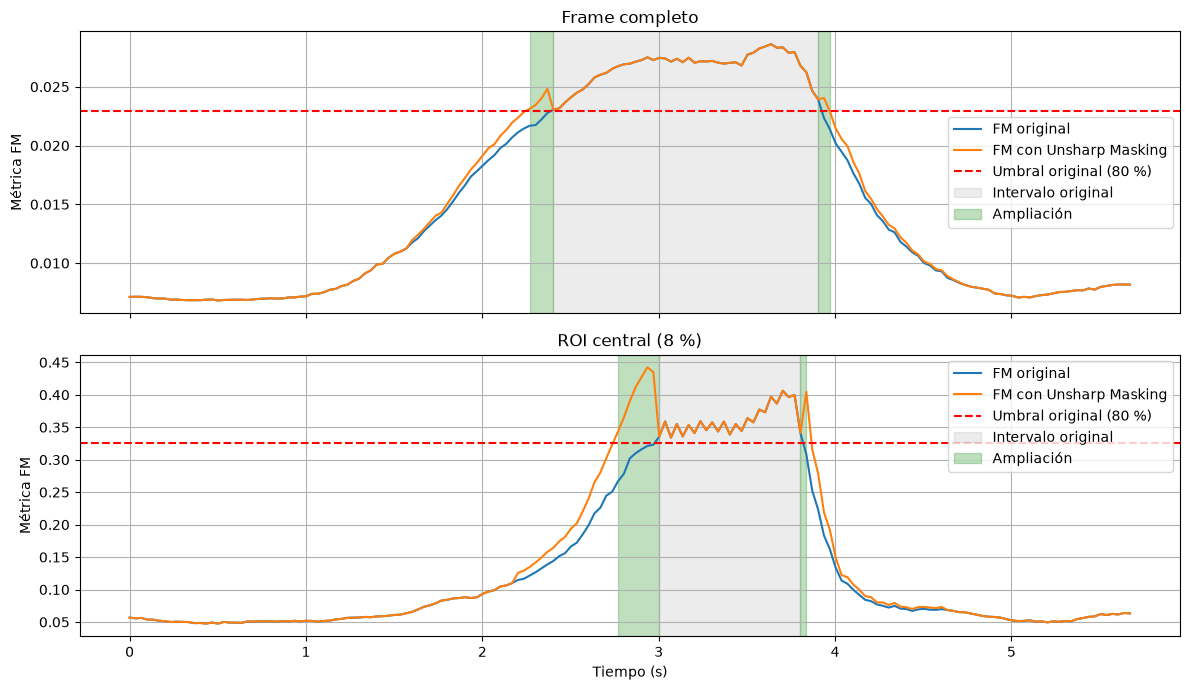

In [13]:

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

resultados = [
    ("Frame completo", fm_completo, fm_completo_extra,
     inicio_completo, fin_completo,
     nuevo_inicio_completo, nuevo_fin_completo,
     umbral_completo),

    ("ROI central (8 %)", fm_roi, fm_roi_extra,
     inicio_roi, fin_roi,
     nuevo_inicio_roi, nuevo_fin_roi,
     umbral_roi)
]

for ax, (nombre, original, realzada,
         inicio, fin, nuevo_inicio, nuevo_fin,
         umbral) in zip(axes, resultados):

    ax.plot(instantes_s, original, label="FM original")
    ax.plot(instantes_s, realzada, label="FM con Unsharp Masking")

    ax.axhline(umbral, color="red", linestyle="--",
               label="Umbral original (80 %)")

    ax.axvspan(instantes_s[inicio], instantes_s[fin],
               color="gray", alpha=0.15,
               label="Intervalo original")

    # Mostrar únicamente la ampliación conseguida
    if nuevo_inicio < inicio:
        ax.axvspan(instantes_s[nuevo_inicio], instantes_s[inicio],
                   color="green", alpha=0.25,
                   label="Ampliación")

    if nuevo_fin > fin:
        ax.axvspan(instantes_s[fin], instantes_s[nuevo_fin],
                   color="green", alpha=0.25)

    ax.set_title(nombre)
    ax.set_ylabel("Métrica FM")
    ax.legend()
    ax.grid(True)

axes[1].set_xlabel("Tiempo (s)")

plt.tight_layout()
plt.show()



### Análisis de resultados

La aplicación de *unsharp masking* permitió ampliar el intervalo clasificado como enfocado en ambos experimentos, manteniendo fijo el umbral de detección original del 80 %.

En el fotograma completo, el intervalo aumentó de 46 a 52 fotogramas, representando una ampliación del **13,0 %**. En la ROI central, aumentó de 25 a 33 fotogramas, equivalente a un incremento del **32,0 %**.

En ambos casos, la ampliación fue mayor hacia el comienzo del intervalo enfocado.

Se observa además que el realce puede producir incrementos pronunciados de FM, incluso superiores al máximo de la curva original. Esto se debe a que el *unsharp masking* intensifica las componentes de alta frecuencia que intervienen en el cálculo de la métrica.

Por lo tanto, **la ampliación del intervalo detectado no implica necesariamente una recuperación del enfoque óptico**, sino una mejora de la respuesta de la métrica frente al realce digital.

Finalmente, la aplicación selectiva del filtro únicamente en las regiones próximas a los límites puede producir discontinuidades en las curvas de FM.



### 7.1. Verificación visual del Unsharp Masking

Para evaluar el efecto del realce digital, se selecciona el fotograma 85, ubicado próximo al límite inicial del intervalo de enfoque.

Este fotograma fue clasificado originalmente como desenfocado para la ROI central, pero quedó incluido en el intervalo enfocado después de aplicar *unsharp masking*.

Se comparan la imagen original y la imagen procesada, junto con sus respectivos valores de FM, para analizar la correspondencia entre el aumento de la métrica y la mejora visual de la nitidez.


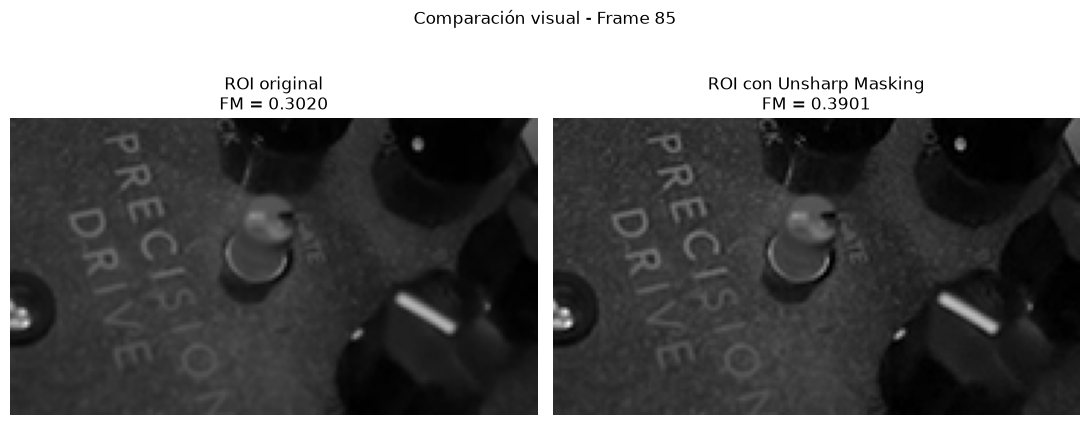

FM original: 0.302026
FM realzada: 0.390099
Incremento de FM: 29.2 %
Umbral original ROI: 0.325035
El fotograma supera el umbral de enfoque.


In [14]:

# Fotograma seleccionado para la comparación
i = 85

# Imagen original y realzada
original = frames_grises[i]
realzada = unsharp_mask(original)

# Extraer la ROI de ambas imágenes
roi_original, _ = recortar_roi_central(original, AREA_ROI)
roi_realzada, _ = recortar_roi_central(realzada, AREA_ROI)

# Calcular las métricas
fm_antes = frecuencia_enfoque(roi_original)
fm_despues = frecuencia_enfoque(roi_realzada)

# Mostrar resultados
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(roi_original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"ROI original\nFM = {fm_antes:.4f}")
axes[0].axis("off")

axes[1].imshow(roi_realzada, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"ROI con Unsharp Masking\nFM = {fm_despues:.4f}")
axes[1].axis("off")

plt.suptitle(f"Comparación visual - Frame {i}")
plt.tight_layout()
plt.show()

# Variación porcentual de FM
incremento = 100 * (fm_despues - fm_antes) / fm_antes

print(f"FM original: {fm_antes:.6f}")
print(f"FM realzada: {fm_despues:.6f}")
print(f"Incremento de FM: {incremento:.1f} %")
print(f"Umbral original ROI: {umbral_roi:.6f}")

if fm_despues >= umbral_roi:
    print("El fotograma supera el umbral de enfoque.")
else:
    print("El fotograma no supera el umbral de enfoque.")



### Análisis de resultados

En el fotograma 85, la aplicación de *unsharp masking* incrementó la métrica FM de 0,3020 a 0,3901, representando un aumento del **29,2 %**.

Como consecuencia, el fotograma pasó de encontrarse por debajo del umbral de enfoque (FM = 0,3250) a superarlo.

Visualmente, se observa un ligero realce de los contornos de las letras y de los elementos presentes en la ROI. Sin embargo, la mejora perceptible resulta moderada en comparación con el incremento de la métrica.

Esto evidencia que **un aumento de FM no necesariamente implica una mejora equivalente en la nitidez visual**, ya que el procesamiento también puede intensificar el ruido y las transiciones de intensidad sin recuperar información óptica perdida.

En consecuencia, el *unsharp masking* permitió ampliar el intervalo de enfoque detectado según el criterio adoptado, aunque sus resultados deben interpretarse como una mejora de la nitidez aparente y no como una restauración completa del enfoque original.



## 8. Conclusiones

Se implementó satisfactoriamente el algoritmo de De y Masilamani (2013) para evaluar el enfoque de imágenes mediante el análisis de su contenido frecuencial. Su aplicación a los 171 fotogramas del video permitió identificar el aumento y la posterior disminución del enfoque, tanto sobre la imagen completa como sobre una ROI central del 8 %.

A partir de los resultados se obtuvieron las siguientes conclusiones:

1. **Detección del máximo enfoque.** Ambos experimentos identificaron máximos temporalmente próximos: el fotograma 109 (3,637 s) para la imagen completa y el 111 (3,704 s) para la ROI. Esto evidencia una buena correspondencia temporal entre las mediciones.

2. **Detección automática del intervalo enfocado.** Mediante un umbral relativo del 80 % del máximo de FM, se identificaron automáticamente los intervalos comprendidos entre los fotogramas 72–117 para la imagen completa y 90–114 para la ROI. Esto permitió representar una región de enfoque aceptable, en lugar de limitar la detección al máximo absoluto.

3. **Influencia de la región analizada.** La ROI presentó una respuesta más localizada temporalmente y mayores fluctuaciones relativas en la región de alto enfoque. Además, sus valores absolutos de FM fueron diferentes de los obtenidos sobre el fotograma completo, lo que demuestra que la métrica depende también del tamaño y del contenido espacial de la región analizada.

4. **Sensibilidad al umbral.** La comparación entre umbrales del 80 %, 85 % y 90 % mostró que el resultado depende considerablemente del criterio adoptado, especialmente para la ROI. En este caso, el intervalo se redujo de 25 a 7 fotogramas al pasar del 80 % al 90 %. Se seleccionó el 80 % por permitir incorporar la meseta de alto enfoque observada en la curva.

5. **Efecto del unsharp masking.** El realce digital amplió los intervalos detectados de 46 a 52 fotogramas para la imagen completa (+13,0 %) y de 25 a 33 para la ROI (+32,0 %). Sin embargo, la comparación visual del fotograma 85 mostró que un incremento de FM del 29,2 % no se correspondió con una mejora visual de igual magnitud.

En conclusión, **la métrica FM permitió caracterizar la evolución temporal del enfoque e identificar automáticamente regiones de mayor nitidez**, utilizando un procedimiento sencillo y de bajo costo computacional.

No obstante, los resultados evidencian que la detección depende de la región seleccionada y del umbral establecido. Asimismo, el incremento de FM mediante técnicas de realce digital no garantiza la recuperación de información perdida por desenfoque óptico.

Por lo tanto, FM constituye un indicador útil para evaluar variaciones relativas del enfoque, aunque sus resultados deben interpretarse considerando las características de la imagen y el procesamiento aplicado.
